Cette démonstration reprend des éléments des exemples de scikit-learn sur [DBSCAN](https://scikit-learn.org/stable/auto_examples/cluster/plot_dbscan.html) et [HDBSCAN](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html).

In [1]:
%matplotlib inline

# Clustering DBSCAN

DBSCAN suit la densité des points. Il a deux réglages : une distance ε (`eps`) et un nombre minimum de voisins (`min_samples`, le *v* des diapositives, le point compris).

- **Point central** : au moins `min_samples` voisins dans son ε-voisinage ;
- **Point de bordure** : pas central, mais voisin d'un point central : il rejoint son cluster ;
- **Bruit** : ni l'un ni l'autre.

Un cluster s'étend de proche en proche entre points centraux voisins.

Les données sont celles de la figure « DBSCAN — Exemple » des diapositives : deux croissants entrelacés ([`make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html)) et 15 points tirés au hasard sur le plan. Des clusters qui ne sont pas ronds, et du bruit : ce que k-means ne sait pas traiter.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

# Deux croissants entrelacés, et 15 points tirés au hasard sur le plan
croissants, etiquettes_croissants = make_moons(
  n_samples=300, noise=0.06, random_state=0
)
rng = np.random.default_rng(0)
X = np.vstack([croissants, rng.uniform((-1.3, -0.8), (2.3, 1.3), size=(15, 2))])


def compter(etiquettes):
  """Nombre de clusters et nombre de points de bruit (label -1)."""
  return len(set(etiquettes) - {-1}), int(np.sum(etiquettes == -1))


def afficher(ax, points, etiquettes, titre, centraux=None):
  """Points centraux pleins, de bordure creux, bruit en croix."""
  bruit = etiquettes == -1
  if centraux is None:
    centraux = ~bruit
  bordure = ~centraux & ~bruit
  ax.scatter(
    *points[centraux].T, s=12, c=etiquettes[centraux], cmap="tab10", vmin=0, vmax=9
  )
  ax.scatter(
    *points[bordure].T,
    s=22,
    facecolors="white",
    edgecolors=plt.cm.tab10(etiquettes[bordure]),
  )
  ax.scatter(*points[bruit].T, s=25, marker="x", color="k")
  ax.set_title(titre)
  ax.set_aspect("equal")
  ax.set_xticks([])
  ax.set_yticks([])

## K-means et DBSCAN côte à côte

K-means avec k = 2, DBSCAN avec ε = 0,2 et `min_samples=5` (le choix de ε vient dans la partie suivante). L'ARI compare les clusters aux deux croissants : 1 = partition identique, ≈ 0 = hasard.

DBSCAN : 2 clusters, 10 points de bruit
303 points centraux, 2 points de bordure
ARI sur les croissants : k-means 0.22, DBSCAN 1.00
Silhouette moyenne : k-means 0.48, DBSCAN 0.32 (sans le bruit)


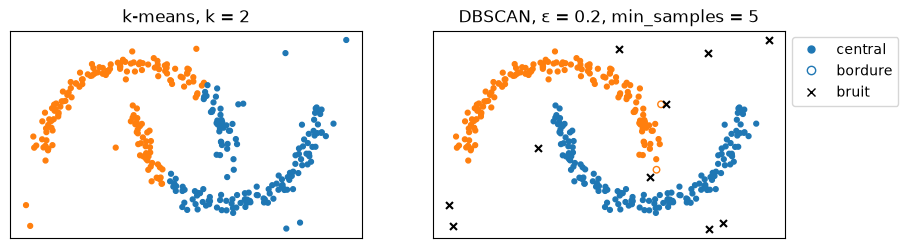

In [3]:
etiquettes_kmeans = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
dbscan = DBSCAN(eps=0.2, min_samples=5).fit(X)
etiquettes = dbscan.labels_
est_central = np.zeros(len(X), dtype=bool)
est_central[dbscan.core_sample_indices_] = True

est_bordure = ~est_central & (etiquettes != -1)
nb_clusters, nb_bruit = compter(etiquettes)
print(f"DBSCAN : {nb_clusters} clusters, {nb_bruit} points de bruit")
print(f"{est_central.sum()} points centraux, {est_bordure.sum()} points de bordure")

# ARI sur les 300 points des croissants, comparés aux deux croissants
ari_kmeans = adjusted_rand_score(etiquettes_croissants, etiquettes_kmeans[:300])
ari_dbscan = adjusted_rand_score(etiquettes_croissants, etiquettes[:300])
print(f"ARI sur les croissants : k-means {ari_kmeans:.2f}, DBSCAN {ari_dbscan:.2f}")
gardes = etiquettes != -1
silhouette_kmeans = silhouette_score(X, etiquettes_kmeans)
silhouette_dbscan = silhouette_score(X[gardes], etiquettes[gardes])
print(f"Silhouette moyenne : k-means {silhouette_kmeans:.2f}, ", end="")
print(f"DBSCAN {silhouette_dbscan:.2f} (sans le bruit)")

fig, (gauche, droite) = plt.subplots(1, 2, figsize=(10, 3.5))
afficher(gauche, X, etiquettes_kmeans, "k-means, k = 2")
afficher(
  droite, X, etiquettes, "DBSCAN, ε = 0.2, min_samples = 5", centraux=est_central
)
droite.legend(
  handles=[
    plt.Line2D([], [], marker="o", ls="", color="C0", markersize=5, label="central"),
    plt.Line2D(
      [], [], marker="o", ls="", mfc="white", mec="C0", markersize=6, label="bordure"
    ),
    plt.Line2D([], [], marker="x", ls="", color="k", label="bruit"),
  ],
  loc="upper left",
  bbox_to_anchor=(1, 1),
)
plt.show()

K-means coupe les croissants en deux moitiés (ARI 0,22) : il cherche des groupes ronds autour de centroïdes, et chaque frontière est à égale distance de deux centroïdes. DBSCAN suit la densité : il retrouve les deux croissants (ARI 1,00) et met en bruit 10 des 15 points ajoutés (les 5 autres sont tombés sur un croissant).

La silhouette moyenne préfère pourtant k-means (0,48 contre 0,32) : elle favorise les clusters ronds et compacts. C'est un indice parmi d'autres.

## Choisir ε : la courbe des k-distances

Pour chaque point, la distance à son 5e voisin (5 = `min_samples`, le point compté parmi ses voisins comme dans DBSCAN), triée. Dans les zones denses, cette distance est petite ; pour le bruit, elle est grande. On prend ε au coude, là où la courbe se redresse.

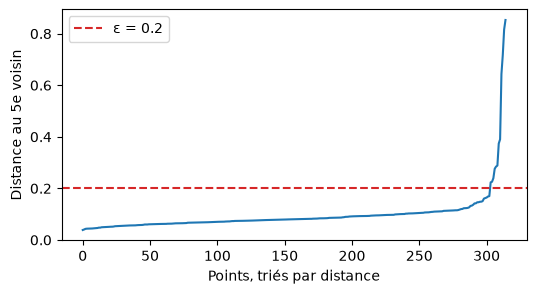

In [4]:
# Distance de chaque point à son 5e voisin, lui compris (comme min_samples)
voisins = NearestNeighbors(n_neighbors=5).fit(X)
distances = np.sort(voisins.kneighbors(X)[0][:, -1])

plt.figure(figsize=(6, 3))
plt.plot(distances)
plt.axhline(0.2, color="C3", ls="--", label="ε = 0.2")
plt.xlabel("Points, triés par distance")
plt.ylabel("Distance au 5e voisin")
plt.legend()
plt.show()

Trois valeurs de ε autour du coude :

ε = 0.1 : 11 cluster(s), 29 points de bruit
ε = 0.2 : 2 cluster(s), 10 points de bruit
ε = 0.3 : 1 cluster(s), 6 points de bruit


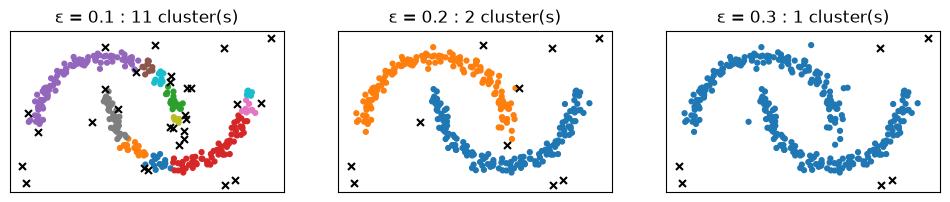

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, eps in zip(axes, (0.1, 0.2, 0.3)):
  etiquettes = DBSCAN(eps=eps, min_samples=5).fit(X).labels_
  nb_clusters, nb_bruit = compter(etiquettes)
  print(f"ε = {eps} : {nb_clusters} cluster(s), {nb_bruit} points de bruit")
  afficher(ax, X, etiquettes, f"ε = {eps} : {nb_clusters} cluster(s)")
plt.show()

ε trop petit (0,1) : les croissants se morcellent en 11 clusters, avec 29 points de bruit. ε trop grand (0,3) : les deux croissants se rejoignent en un seul cluster. Au coude, ε = 0,2 les sépare.

## HDBSCAN

[HDBSCAN](https://scikit-learn.org/stable/modules/clustering.html#hdbscan) (`sklearn.cluster.HDBSCAN`, scikit-learn ≥ 1.3), c'est DBSCAN sur toutes les valeurs de ε : il garde les clusters qui durent le plus longtemps quand ε varie. Plus de ε à régler, des densités variables, et un seul réglage : la taille minimale d'un cluster (`min_cluster_size`).

Sur les croissants, sans ε :

In [6]:
# copy=True : HDBSCAN ne modifie pas X (le défaut à partir de scikit-learn 1.10)
etiquettes = HDBSCAN(min_cluster_size=10, copy=True).fit(X).labels_
nb_clusters, nb_bruit = compter(etiquettes)
print(f"HDBSCAN : {nb_clusters} clusters, {nb_bruit} points de bruit, ", end="")
print(
  f"ARI sur les croissants {adjusted_rand_score(etiquettes_croissants, etiquettes[:300]):.2f}"
)

HDBSCAN : 2 clusters, 11 points de bruit, ARI sur les croissants 0.99


Sur quatre groupes de densités très différentes, deux serrés et proches, deux diffus (le jeu de la partie « Multi-Scale Clustering » de la page [Demo of HDBSCAN clustering algorithm](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html) de scikit-learn), un seul ε ne convient pas à tous les clusters :

DBSCAN, ε = 0.2 : 9 clusters, 342 points de bruit, ARI 0.65
DBSCAN, ε = 0.8 : 3 clusters, 14 points de bruit, ARI 0.66
HDBSCAN, min_cluster_size = 20 : 4 clusters, 80 points de bruit, ARI 0.84


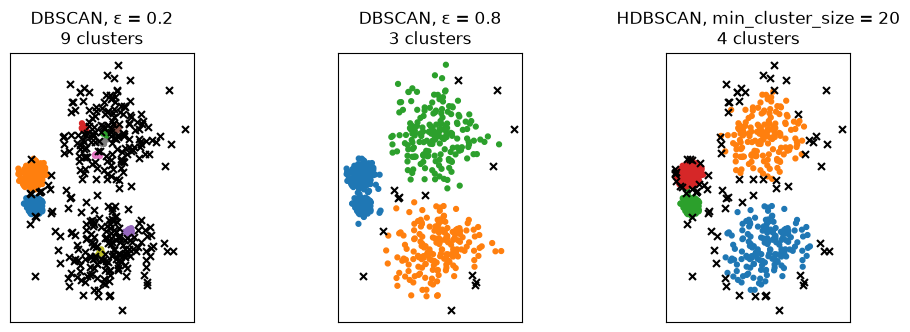

In [7]:
amas, etiquettes_amas = make_blobs(
  n_samples=750,
  centers=[[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]],
  cluster_std=[0.2, 0.35, 1.35, 1.35],
  random_state=0,
)
modeles = {
  "DBSCAN, ε = 0.2": DBSCAN(eps=0.2, min_samples=5),
  "DBSCAN, ε = 0.8": DBSCAN(eps=0.8, min_samples=5),
  "HDBSCAN, min_cluster_size = 20": HDBSCAN(min_cluster_size=20, copy=True),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (titre, modele) in zip(axes, modeles.items()):
  etiquettes = modele.fit(amas).labels_
  nb_clusters, nb_bruit = compter(etiquettes)
  ari = adjusted_rand_score(etiquettes_amas, etiquettes)
  print(f"{titre} : {nb_clusters} clusters, {nb_bruit} points de bruit, ARI {ari:.2f}")
  afficher(ax, amas, etiquettes, f"{titre}\n{nb_clusters} clusters")
plt.show()

In [8]:
# Le meilleur ε de DBSCAN, choisi en connaissant les groupes d'origine
valeurs_eps = np.arange(0.05, 1.5, 0.05)
scores_ari = [
  adjusted_rand_score(etiquettes_amas, DBSCAN(eps=eps, min_samples=5).fit(amas).labels_)
  for eps in valeurs_eps
]
meilleur = np.argmax(scores_ari)
print(
  f"Meilleur DBSCAN : ε = {valeurs_eps[meilleur]:.2f}, ARI {scores_ari[meilleur]:.2f}"
)
for taille in (10, 40):
  etiquettes = HDBSCAN(min_cluster_size=taille, copy=True).fit(amas).labels_
  nb_clusters, nb_bruit = compter(etiquettes)
  ari = adjusted_rand_score(etiquettes_amas, etiquettes)
  print(
    f"HDBSCAN, min_cluster_size = {taille} : {nb_clusters} clusters, "
    f"{nb_bruit} points de bruit, ARI {ari:.2f}"
  )

Meilleur DBSCAN : ε = 0.85, ARI 0.67
HDBSCAN, min_cluster_size = 10 : 4 clusters, 55 points de bruit, ARI 0.89
HDBSCAN, min_cluster_size = 40 : 4 clusters, 127 points de bruit, ARI 0.76


Avec ε = 0,2, les deux groupes serrés sont séparés, mais les deux groupes diffus se morcellent (9 clusters, 342 points de bruit) ; avec ε = 0,8, les groupes diffus sont retrouvés, mais les deux groupes serrés fusionnent (3 clusters). Même choisi en connaissant les groupes d'origine, le meilleur ε (0,85) ne dépasse pas un ARI de 0,67. HDBSCAN trouve les 4 groupes (ARI 0,84), et les garde pour une taille minimale de 10 à 40 : un réglage peu sensible. Il range en bruit les points épars des groupes diffus, d'autant plus que la taille minimale est grande, ce qui fait baisser son ARI (de 0,89 à 0,76).